# Development archive — Part 2

Historical API probes, budget estimates, storage audits and pilot-stage notes removed from the submission notebook. These are development records, not the current completion status. Saved outputs are preserved. See ../prosjekt_part2.ipynb for the final analysis.


## 6. Test a small ENTSO-E cross-border API request

Before retrieving two years of data, test **NO2 ↔ DK1 for 1 January 2026**.
This section runs independently of Spark, Docker and MongoDB.

The [D2D REST notebook](https://github.com/khliland/IND320/blob/main/D2Dbook/2_Data_sources/3_APIs/2_REST.ipynb)
uses `requests.get`. The [D2D API Tokens notebook](https://github.com/khliland/IND320/blob/main/D2Dbook/2_Data_sources/3_APIs/4_API_Tokens.ipynb)
demonstrates BarentsWatch credentials, not a ready-made ENTSO-E implementation.
Here I adapt the GET workflow to ENTSO-E's persistent security token and XML
responses. Credentials stay in the ignored `.streamlit/secrets.toml` under
`[entsoe] token`, as chosen for this project. TLS verification remains enabled.

The request uses physical flows (`documentType=A11`). `out_Domain` is the
origin and `in_Domain` the destination; each direction needs its own request.
EICs are NO2 `10YNO-2--------T` and DK1 `10YDK-1--------W`.
The Norwegian calendar day is converted from Europe/Oslo to UTC for the API.

Sources: [API reference](https://documenter.getpostman.com/view/7009892/2s93JtP3F6),
[endpoint](https://transparencyplatform.zendesk.com/hc/en-us/articles/15696677194644-Request-Endpoint),
[area codes](https://transparencyplatform.zendesk.com/hc/en-us/articles/15885757676308-Area-List-with-Energy-Identification-Code-EIC),
[request dates](https://transparencyplatform.zendesk.com/hc/en-us/articles/15696716612372-Request-Parameters),
and [direction and response semantics](https://transparencyplatform.zendesk.com/hc/en-us/articles/15727773247124-Query-Response).

### 6.1 Fetch at most two small XML responses

Each response has a 128 KiB decoded-body limit; there are no automatic retries.
Successful XML is cached in `no_sync/entsoe_cache/`. Rerunning the cell reuses
these files without another request. No database is read or written. Errors
never print the request URL, token, response body or original exception.


In [11]:
from pathlib import Path
from datetime import datetime, timedelta, timezone
from zoneinfo import ZoneInfo
import sys
import xml.etree.ElementTree as ET
import pandas as pd

entsoe_root = Path.cwd()
if entsoe_root.name == "notebooks":
    entsoe_root = entsoe_root.parent
if str(entsoe_root) not in sys.path:
    sys.path.insert(0, str(entsoe_root))
from pipeline.entsoe_data import load_flow_xml

entsoe_cache = entsoe_root / "no_sync" / "entsoe_cache"
ENTSOE_SAMPLE_LIMIT = 128 * 1024
sample_start = datetime(2026, 1, 1, tzinfo=ZoneInfo("Europe/Oslo"))
sample_end = sample_start + timedelta(days=1)
start_utc, end_utc = (date.astimezone(timezone.utc) for date in (sample_start, sample_end))
no2, dk1 = "10YNO-2--------T", "10YDK-1--------W"
sample_xml = {}
sample_download_bytes = 0
for direction, origin, destination in [("export", no2, dk1), ("import", dk1, no2)]:
    # The same persistent download budget is shared by sections 6, 7 and 9.
    body, downloaded = load_flow_xml(
        entsoe_root, origin, destination, sample_start, sample_end,
        f"NO2_DK1_2026-01-01_{direction}.xml",
        max_response_bytes=ENTSOE_SAMPLE_LIMIT,
    )
    sample_xml[direction] = ET.fromstring(body)
    sample_download_bytes += downloaded
    source = "API" if downloaded else "local cache"
    print(f"{direction}: {len(body):,} XML bytes ({source})")
print(f"New decoded response bytes this run: {sample_download_bytes:,}")
print(f"Requested UTC interval: {start_utc.isoformat()} to {end_utc.isoformat()} (exclusive)")


export: 1,627 XML bytes (local cache)
import: 13,427 XML bytes (local cache)
New decoded response bytes this run: 0
Requested UTC interval: 2025-12-31T23:00:00+00:00 to 2026-01-01T23:00:00+00:00 (exclusive)


### 6.2 Inspect the returned series before expanding the download

Inspect direction, units, resolution and point counts first. Below the overview,
show all points from each call in separate export and import tables. The values below
are raw XML points, not yet a regular hourly table or an energy total.

ENTSO-E may use [A03 variable-sized blocks](https://transparencyplatform.zendesk.com/hc/en-us/articles/30262342482961-CurveType-A01-vs-CurveType-A03).
A point can describe a value lasting until the next change; missing positions
must not automatically become zero. Proper interval reconstruction and
`MW × hours = MWh` conversion are required before annual energy pie charts.
This sample only checks access and the returned structure.


In [2]:
# Namespace wildcards allow the XML schema version to vary.
series_overview = []
raw_sample_points = []
for direction, root in sample_xml.items():
    for series in root.findall("{*}TimeSeries"):
        for period in series.findall("{*}Period"):
            points = period.findall("{*}Point")
            series_overview.append({
                "direction_relative_to_Norway": direction,
                "unit": series.findtext("{*}quantity_Measure_Unit.name"),
                "curve_type": series.findtext("{*}curveType"),
                "period_start_utc": period.findtext("{*}timeInterval/{*}start"),
                "period_end_utc": period.findtext("{*}timeInterval/{*}end"),
                "resolution": period.findtext("{*}resolution"),
                "raw_point_count": len(points),
            })
            for point in points:
                raw_sample_points.append({
                    "direction": direction,
                    "period_start_utc": period.findtext("{*}timeInterval/{*}start"),
                    "position": int(point.findtext("{*}position")),
                    "quantity": float(point.findtext("{*}quantity")),
                })
series_overview = pd.DataFrame(series_overview)
raw_sample_points = pd.DataFrame(raw_sample_points)
if raw_sample_points.empty:
    raise RuntimeError("The sample contains no quantity points.")
print("Connection test passed: data returned for both directions.")
print(f"Raw XML points: {len(raw_sample_points):,}")
display(series_overview)
# Show the complete raw point table from each call separately. These are
# XML positions at PT15M resolution, not yet reconstructed energy intervals.
for direction, label in [
    ("export", "EXPORT: NO2 → DK1 (Norway to Denmark)"),
    ("import", "IMPORT: DK1 → NO2 (Denmark to Norway)"),
]:
    direction_points = raw_sample_points.loc[
        raw_sample_points["direction"].eq(direction)
    ].reset_index(drop=True)
    print(f"\n{label} — {len(direction_points)} raw points")
    print("quantity is power in MW (API unit code MAW); position starts at 1.")
    # Both responses are small, so show every row rather than truncating.
    with pd.option_context("display.max_rows", 100, "display.max_columns", None):
        display(direction_points)


Connection test passed: data returned for both directions.
Raw XML points: 98


,direction_relative_to_Norway,unit,curve_type,period_start_utc,period_end_utc,resolution,raw_point_count
0,export,MAW,A03,2025-12-31T23:00Z,2026-01-01T23:00Z,PT15M,2
1,import,MAW,A03,2025-12-31T23:00Z,2026-01-01T23:00Z,PT15M,96



EXPORT: NO2 → DK1 (Norway to Denmark) — 2 raw points
quantity is power in MW (API unit code MAW); position starts at 1.


,direction,period_start_utc,position,quantity
0,export,2025-12-31T23:00Z,1,0.19
1,export,2025-12-31T23:00Z,2,0.00



IMPORT: DK1 → NO2 (Denmark to Norway) — 96 raw points
quantity is power in MW (API unit code MAW); position starts at 1.


,direction,period_start_utc,position,quantity
0,import,2025-12-31T23:00Z,1,968.035633
1,import,2025-12-31T23:00Z,2,1151.978452
2,import,2025-12-31T23:00Z,3,1370.039586
3,import,2025-12-31T23:00Z,4,1559.266929
4,import,2025-12-31T23:00Z,5,1422.758098
5,import,2025-12-31T23:00Z,6,1583.896565
6,import,2025-12-31T23:00Z,7,1604.639679
7,import,2025-12-31T23:00Z,8,1604.658926
8,import,2025-12-31T23:00Z,9,1604.429119
9,import,2025-12-31T23:00Z,10,1604.652774


### 6.3 Sample result and next step

The live test succeeded on 10 October 2026. The two decoded XML responses
contained **15,054 bytes** in total: 1,627 bytes for export and 13,427 for import.
Both cover 1 January 2026 in Europe/Oslo, from 2025-12-31 23:00 UTC to
2026-01-01 23:00 UTC (exclusive). Both use `PT15M` resolution and A03 curves.
There are **98 raw points**: 2 export change points and 96 import change points.
These counts are not a count of hourly observations and must not be summed
as energy. ENTSO-E's `MAW` unit code represents MW.

A second run with network calls disabled reused both cached responses and
downloaded **0 bytes**. Offline checks also verified the response-size cutoff,
connection closure on overflow, redacted network errors, invalid XML handling,
and rejection of acknowledgement-only responses. The notebook contains no token.
No Cassandra or MongoDB data was created or modified.

Section 6.4 below reconstructs and explains this sample. Next, estimate the
two-year storage budget before bulk downloads and Spark/Cassandra ingestion. One sampled day alone cannot establish the
size or coverage of every connection over two years.


### 6.4 What happened on this connection during the day?

The raw positions become easier to interpret after converting them to Norwegian
clock time. This section uses the **same two cached responses**, with no API or
database access. Run section 6.1 first to load them into `sample_xml`.

- **Import:** electricity flowing from western Denmark (DK1) to southern Norway (NO2).
- **Export:** electricity flowing from NO2 to DK1.
- **MW** describes power during an interval. **MWh** describes energy over time.
  For example, 1,000 MW over 15 minutes equals 250 MWh.

The samples use A03: a value remains in effect until the next change, or until
its XML period ends. This follows [ENTSO-E's curve specification, section 4.3](https://eepublicdownloads.entsoe.eu/clean-documents/EDI/Library/cim_based/Introduction_of_different_Timeseries_possibilities__curvetypes__with_ENTSO-E_electronic_document_v1.4.pdf).
We expand only these complete 15-minute sample periods. The checks stop on
missing initial data, invalid values, unexpected formats or different coverage;
this is not yet a general parser for the two-year download.


In [2]:
import math

# This small parser is deliberately restricted to the format verified in our
# one-day sample. Other periods/formats need separate validation before use.
def expand_sample_a03(root):
    series = root.findall("{*}TimeSeries")
    if len(series) != 1:
        raise ValueError("Expected exactly one series in this sample.")
    series = series[0]
    periods = series.findall("{*}Period")
    if (series.findtext("{*}curveType") != "A03"
            or series.findtext("{*}quantity_Measure_Unit.name") != "MAW"
            or len(periods) != 1):
        raise ValueError("Expected one A03 period measured in MW.")
    period = periods[0]
    start = pd.Timestamp(period.findtext("{*}timeInterval/{*}start"))
    end = pd.Timestamp(period.findtext("{*}timeInterval/{*}end"))
    if (period.findtext("{*}resolution") != "PT15M"
            or start != pd.Timestamp(start_utc) or end != pd.Timestamp(end_utc)):
        raise ValueError("Unexpected sample resolution or date coverage.")
    grid = pd.date_range(start, end, freq="15min", inclusive="left")
    points = {}
    for point in period.findall("{*}Point"):
        position = int(point.findtext("{*}position"))
        quantity = float(point.findtext("{*}quantity"))
        if (position in points or not 1 <= position <= len(grid)
                or not math.isfinite(quantity) or quantity < 0):
            raise ValueError("Invalid or duplicate sample point.")
        points[position] = quantity
    if 1 not in points:
        raise ValueError("The initial value is missing; do not assume zero.")
    # In A03, omitted positions repeat the latest value WITHIN this period.
    values = pd.Series(points, dtype=float).reindex(range(1, len(grid) + 1)).ffill()
    return pd.Series(values.to_numpy(), index=grid, name="power_mw")


sample_power = pd.DataFrame({
    direction: expand_sample_a03(root) for direction, root in sample_xml.items()
})
if sample_power.isna().any().any() or len(sample_power) != 96:
    raise ValueError("Expected 96 complete 15-minute intervals in both directions.")
# Each row is 15 minutes = 0.25 hours. Summing MW alone would not give MWh.
sample_energy_mwh = sample_power * 0.25
sample_daily_mwh = sample_energy_mwh.sum()
sample_power.index = sample_power.index.tz_convert("Europe/Oslo")

print("NO2 ↔ DK1 — 1 January 2026, Norwegian time")
print(f"Energy imported from Denmark: {sample_daily_mwh['import']:,.3f} MWh")
print(f"Energy exported to Denmark: {sample_daily_mwh['export']:,.4f} MWh "
      f"({sample_daily_mwh['export'] * 1000:.1f} kWh)")
print(f"Net import: {sample_daily_mwh['import'] - sample_daily_mwh['export']:,.3f} MWh")
print("\nThe first two hours, with actual clock times:")
readable_sample = pd.DataFrame({
    "Norwegian time interval": [
        f"{time:%H:%M}–{time + pd.Timedelta(minutes=15):%H:%M}"
        for time in sample_power.index
    ],
    "Import from DK1 (MW)": sample_power['import'].to_numpy(),
    "Export to DK1 (MW)": sample_power['export'].to_numpy(),
    "Imported energy (MWh)": sample_energy_mwh['import'].to_numpy(),
    "Exported energy (MWh)": sample_energy_mwh['export'].to_numpy(),
})
display(readable_sample.head(8).round(4))


NO2 ↔ DK1 — 1 January 2026, Norwegian time
Energy imported from Denmark: 30,182.323 MWh
Energy exported to Denmark: 0.0475 MWh (47.5 kWh)
Net import: 30,182.275 MWh

The first two hours, with actual clock times:


,Norwegian time interval,Import from DK1 (MW),Export to DK1 (MW),Imported energy (MWh),Exported energy (MWh)
0,00:00–00:15,968.0356,0.19,242.0089,0.0475
1,00:15–00:30,1151.9785,0.00,287.9946,0.0000
2,00:30–00:45,1370.0396,0.00,342.5099,0.0000
3,00:45–01:00,1559.2669,0.00,389.8167,0.0000
4,01:00–01:15,1422.7581,0.00,355.6895,0.0000
5,01:15–01:30,1583.8966,0.00,395.9741,0.0000
6,01:30–01:45,1604.6397,0.00,401.1599,0.0000
7,01:45–02:00,1604.6589,0.00,401.1647,0.0000


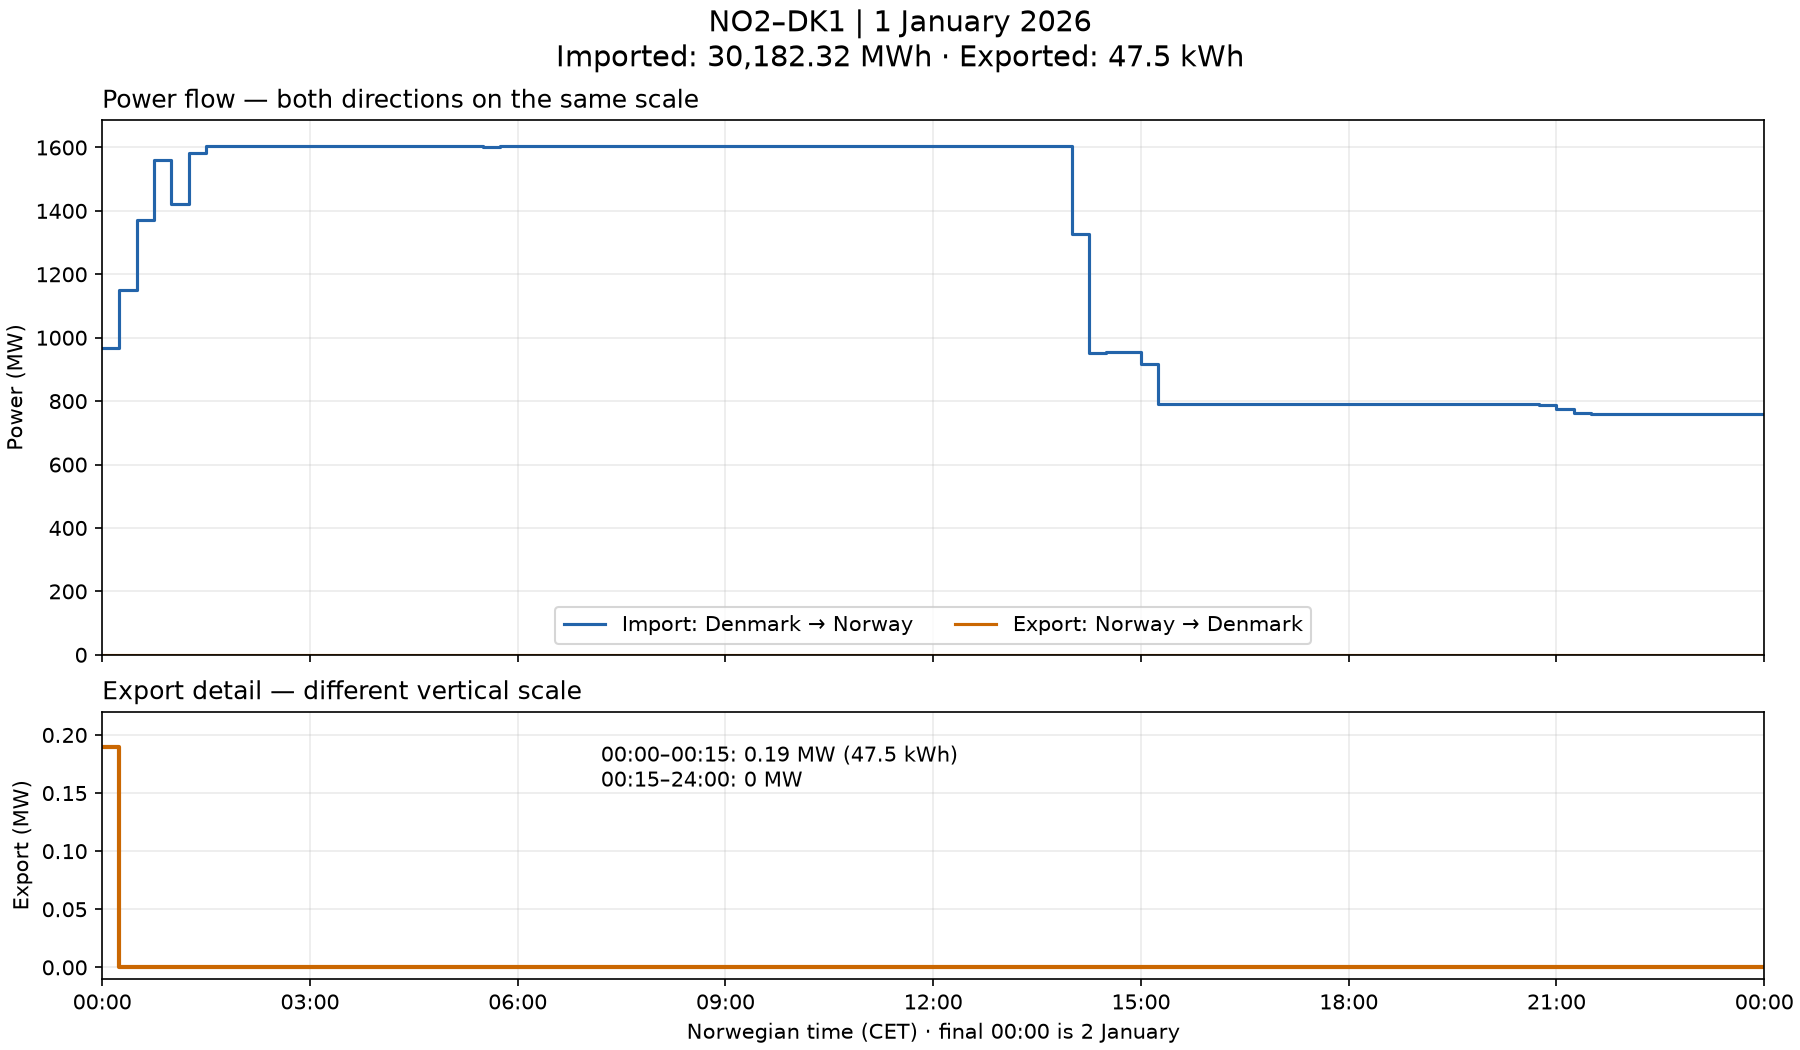

In [3]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# A step plot represents constant power in each 15-minute interval. Include the
# exclusive end of the day so the last interval appears with its full duration.
plot_times = list(sample_power.index) + [pd.Timestamp(end_utc).tz_convert("Europe/Oslo")]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]}, layout="constrained")
for direction, label, colour in [
    ("import", "Import: Denmark → Norway", "#2364aa"),
    ("export", "Export: Norway → Denmark", "#ca6702"),
]:
    values = sample_power[direction].tolist()
    axes[0].step(plot_times, values + [values[-1]], where="post", label=label, color=colour)
axes[0].set_title("Power flow — both directions on the same scale", loc="left")
axes[0].set_ylabel("Power (MW)")
axes[0].set_ylim(bottom=0)
axes[0].legend(loc="lower center", ncol=2)

# Export is tiny compared with import, so show it again with a clearly labelled
# separate scale. Heights between the two panels must not be compared directly.
exports = sample_power['export'].tolist()
axes[1].step(plot_times, exports + [exports[-1]], where="post", color="#ca6702", linewidth=2)
axes[1].set_title("Export detail — different vertical scale", loc="left")
axes[1].set_ylabel("Export (MW)")
axes[1].set_ylim(-0.01, 0.22)
axes[1].text(0.30, 0.72, "00:00–00:15: 0.19 MW (47.5 kWh)\n00:15–24:00: 0 MW",
             transform=axes[1].transAxes)
axes[1].set_xlabel("Norwegian time (CET) · final 00:00 is 2 January")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.set_xlim(plot_times[0], plot_times[-1])
axes[1].xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 3), tz=ZoneInfo("Europe/Oslo")))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=ZoneInfo("Europe/Oslo")))
fig.suptitle("NO2–DK1 | 1 January 2026\n"
             f"Imported: {sample_daily_mwh['import']:,.2f} MWh · Exported: {sample_daily_mwh['export'] * 1000:.1f} kWh",
             fontsize=14)
# The figure is also saved locally for inspection; no data leaves the computer.
sample_plot_path = entsoe_cache / "NO2_DK1_2026-01-01_explained.png"
fig.savefig(sample_plot_path, dpi=150)
plt.show()


### Interpretation of this test day

On **this connection and this day**, Norway mainly received electricity from
Denmark: approximately **30,182 MWh (30.18 GWh)** imported, compared with only
**0.0475 MWh (47.5 kWh)** exported.

The two export points mean **0.19 MW from 00:00 to 00:15**, then **0 MW until
midnight**. This is why two raw points can describe a complete day. Import varies
throughout the day, so its response contains many more change points.

For the first interval, import is approximately **968 MW**. Over 15 minutes,
that corresponds to **242 MWh**. The graph shows power; the daily totals sum
energy across all intervals. It does not show prices, profits or the reason
for the flows. These findings do not describe Norway's other borders or the
rest of the year. The annual pie chart and monthly line chart required by the
assignment still need the larger data collection.


### 8.2 Estimate volume and define stop limits

Native intervals stay in local Cassandra. Spark will calculate energy in each
UTC hour and pair the two directions into **one MongoDB document per connection
and hour**. This preserves hourly curves and annual MWh sums while avoiding two
separate hourly documents. The original intervals remain available in Cassandra.
Coverage minutes accompany each direction: missing data is not zero, and an
incomplete hour must not be presented as a complete hourly mean.

A BSON example measures document payload size. The **2× payload scenario** below
allows room for indexes and uncertainty, but is not a measurement or guarantee
of future Atlas size. The actual aggregate `dataSize + indexSize` must be
checked before and during any upload. The MongoDB project budget is 64 MiB;
the stricter whole-cluster stop threshold is 256 MiB. These are project choices,
not paid service limits. Atlas documents a **0.5 GB free storage limit including
uncompressed BSON and indexes**, 100 operations/second, and 10 GB of transfer
in each direction per rolling seven days. [Atlas limits](https://www.mongodb.com/docs/atlas/reference/free-shared-limitations/).

We plan at most 40 document writes/second and a pool of two connections, leaving
headroom for reads and other use. That is a planning ceiling, not permission
to ignore throttling; stop on quota/rate errors. Streamlit will later request
only a chosen connection/month, with bounded projections and caching.

API size and Cassandra row estimates extrapolate the measured NO2–DK1/2025
sample. Other connections, years and resolutions can differ substantially.
The dense-row scenario assumes at most one value every 15 minutes, per
direction. Finer resolutions or revisions require reassessment, not a silent
increase in limits. Cassandra's 1 GiB volume budget includes local database
files and commit logs, but excludes the Docker image and other containers.
Keep at least 5 GiB free on the host and check Docker's own disk availability.


In [14]:
# A longest planned connection name provides a cautious fixed-schema example.
example_document = {
    "_id": "NO2-DE-LU|20250101T0000Z",
    "connection": "NO2-DE-LU",
    "time_utc": datetime(2025, 1, 1, tzinfo=timezone.utc),
    "import_mwh": 1234.5,
    "export_mwh": 0.0,
    "import_coverage_minutes": 60,
    "export_coverage_minutes": 60,
}
bytes_per_document = len(BSON.encode(example_document))
planned_documents = planned_hours * len(connections)
payload_bytes = bytes_per_document * planned_documents
mongo_budget_scenario = 2 * payload_bytes
sample_files = [plan_root / "no_sync" / "entsoe_cache" / f"NO2_DK1_2025_{d}.xml" for d in ("import", "export")]
sample_xml_bytes = sum(path.stat().st_size for path in sample_files)
# Section 7 measured 29,020 native intervals over 8,760 hours in both directions.
scaling = planned_hours / 8760 * len(connections)
dense_rows = planned_hours * 4 * 2 * len(connections)
limits = plan["planned_limits"]
estimates = pd.DataFrame([
    {"item": "XML cache, sample-based scenario", "estimate": f"{sample_xml_bytes * scaling / 1024**2:.2f} MiB", "planned_stop": "100 MiB new downloads; 128 MiB total cache"},
    {"item": "Native intervals, sample-based scenario", "estimate": f"{round(29020 * scaling):,} rows", "planned_stop": f"{limits['max_raw_rows']:,} rows total"},
    {"item": "Native intervals, dense 15-minute scenario", "estimate": f"{dense_rows:,} rows", "planned_stop": "100,000 rows per Spark write"},
    {"item": "Paired hourly MongoDB documents", "estimate": f"{planned_documents:,} documents", "planned_stop": f"{limits['max_mongo_documents']:,} documents"},
    {"item": "MongoDB BSON payload", "estimate": f"{payload_bytes / 1024**2:.2f} MiB ({bytes_per_document} bytes/document)", "planned_stop": "Measure actual BSON before upload"},
    {"item": "MongoDB 2× payload scenario", "estimate": f"{mongo_budget_scenario / 1024**2:.2f} MiB", "planned_stop": "64 MiB project data + indexes; 256 MiB whole cluster"},
])
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(estimates)
assert planned_documents <= limits["max_mongo_documents"]
assert dense_rows <= limits["max_raw_rows"]
assert mongo_budget_scenario <= limits["max_mongo_project_data_plus_indexes_bytes"]

# Read an already saved metadata audit, not credentials or database documents.
audit_path = plan_root / "no_sync" / "mongo_storage_audit.json"
if audit_path.exists():
    audit = json.loads(audit_path.read_text())
    if audit.get("status") == "ok":
        used = audit["data_bytes"] + audit["index_bytes"]
        print(f"Saved read-only Atlas audit ({audit['checked_at_utc']}):")
        print(f"{audit['documents']} document(s); {audit['data_bytes']:,} data bytes + {audit['index_bytes']:,} index bytes.")
        print(f"Current logical usage plus planning scenario: {(used + mongo_budget_scenario) / 1024**2:.2f} MiB.")
        assert used + mongo_budget_scenario < limits["max_mongo_cluster_data_plus_indexes_bytes"]
    else:
        print("Atlas storage was not measurable: block uploads until a fresh size check succeeds.")
else:
    print("No saved Atlas audit: perform a fresh read-only storage check before any upload.")
print("No downloads or database writes were performed by these planning cells.")


,item,estimate,planned_stop
0,"XML cache, sample-based scenario",61.81 MiB,100 MiB new downloads; 128 MiB total cache
1,"Native intervals, sample-based scenario","522,360 rows","1,300,000 rows total"
2,"Native intervals, dense 15-minute scenario","1,261,440 rows","100,000 rows per Spark write"
3,Paired hourly MongoDB documents,"157,680 documents","160,000 documents"
4,MongoDB BSON payload,27.22 MiB (181 bytes/document),Measure actual BSON before upload
5,MongoDB 2× payload scenario,54.44 MiB,64 MiB project data + indexes; 256 MiB whole cluster


Saved read-only Atlas audit (2026-10-11T10:40:16.038064+00:00):
1 document(s); 86 data bytes + 36,864 index bytes.
Current logical usage plus planning scenario: 54.47 MiB.
No downloads or database writes were performed by these planning cells.


### 8.3 Controlled execution order and remaining safeguards

1. Check one completed day in each untested border/direction (`A11`); reuse
   existing samples. Record status and EIC pair. Authentication failures,
   unsupported borders and missing data stop that border for review.
2. Download guards are now enforced by `pipeline/entsoe_budget.py`: 100 MiB of new
   decoded responses, 128 MiB total cache, 80 attempts, at least one second
   between requests, 8 MiB per response (128 KiB for probes), and 5 GiB free
   host space. A local ledger persists across reruns and reserves bytes before
   requests. Interrupted requests block further downloads pending review.
   There are no automatic retries or limit increases. Section 10 now verifies database-volume and raw-row guards.
   The bulk coordinator must use this guarded writer for every batch.
3. Retrieve one border/direction/year segment at a time, reuse the two cached
   2025 responses, and validate UTC coverage, units, curves, duplicates and
   interval boundaries. If a response exceeds its limit, stop and reconsider
   request segmentation within the same global budget.
4. Insert validated intervals using Spark into bounded Cassandra partitions.
   Count all rows, monitor the full Docker volume, and stop at the stated limits.
   Reuse unchanged snapshots; source revisions with changed interval starts
   need controlled partition replacement or versioning to prevent stale rows.
5. Use Spark to split intervals at UTC-hour boundaries, preserving energy and
   coverage. Check that complete-hour MWh sums agree with the raw interval sums.
6. Before MongoDB upload, measure real BSON payload and current cluster usage.
   Use stable IDs, one bounded collection and only the necessary indexes.
   Check actual document-plus-index size after small batches; stop rather than
   approach the free limit. Restarting must not create duplicate documents.

This section is the plan and budget calculation only. It does not certify that
all border/period data exists, perform bulk downloads, or write curated MongoDB
data. The existing 2025 figures remain valid for their selected connection.


## 9. Verify all planned borders with small API samples

### 9.1 One complete day before expanding the dataset

We request **1 January 2026, 00:00–24:00 Europe/Oslo** for the eight remaining
borders, in both directions. The existing NO2–DK1 samples are reused. This
follows the course's HTTP GET workflow; the project adds XML interval decoding,
cache reuse and persistent limits. No database is needed or written in this step.

The initial run made **16 new requests**, receiving **117,484 decoded bytes
(114.73 KiB)** in total. Each response was limited to 128 KiB. HTTP overhead is
not included. All **18 border/direction pairs** cover the complete 24 hours.
The guard ledger starts with this stage; earlier cached downloads consume cache
space but are not counted again as new traffic. The ledger and XML files stay
in Git-ignored `no_sync/`. Keep the ledger when rerunning: deleting it would
remove the history used to enforce cumulative limits.

The cell below is **cache-only by default**. It shows energy totals from the
validated intervals; zero means the API explicitly reported zero flow with
full coverage. Unavailable data would remain missing, not be converted to zero.


In [15]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display

probe_root = Path.cwd()
if probe_root.name == "notebooks":
    probe_root = probe_root.parent
if str(probe_root) not in sys.path:
    sys.path.insert(0, str(probe_root))
from pipeline.entsoe_probes import run_probes

# Keep False to display cached results without further API traffic.
ALLOW_PROBE_DOWNLOADS = False
probe_report = run_probes(probe_root, allow_download=ALLOW_PROBE_DOWNLOADS)
probe_rows = pd.DataFrame(probe_report["rows"])
summary_rows = []
for connection, rows in probe_rows.groupby("connection", sort=False):
    rows = rows.set_index("direction")
    imports, exports = rows.loc["import"], rows.loc["export"]
    complete = all(rows["status"].eq("complete"))
    summary_rows.append({
        "Connection": connection,
        "Import to Norway (MWh)": imports.energy_mwh,
        "Export from Norway (MWh)": exports.energy_mwh,
        "Net import (MWh)": imports.energy_mwh - exports.energy_mwh if complete else None,
        "Import coverage (hours)": imports.covered_hours,
        "Export coverage (hours)": exports.covered_hours,
        "Data status": "Complete" if complete else "; ".join(rows["status"].astype(str)),
    })
probe_summary = pd.DataFrame(summary_rows)
display(probe_summary.style.format({
    "Import to Norway (MWh)": "{:,.3f}",
    "Export from Norway (MWh)": "{:,.3f}",
    "Net import (MWh)": "{:,.3f}",
    "Import coverage (hours)": "{:.0f}",
    "Export coverage (hours)": "{:.0f}",
}, na_rep="Unavailable").hide(axis="index"))
print(f"New API requests this run: {probe_report['new_requests_this_run']}")
print(f"New decoded bytes this run: {probe_report['new_bytes_this_run']:,}")
print("Database writes: 0")


Connection,Import to Norway (MWh),Export from Norway (MWh),Net import (MWh),Import coverage (hours),Export coverage (hours),Data status
NO1-SE3,"32,893.903",0.000,"32,893.903",24,24,Complete
NO3-SE2,"13,395.520",0.000,"13,395.520",24,24,Complete
NO4-SE1,"4,744.799",49.766,"4,695.034",24,24,Complete
NO4-SE2,"1,389.959",17.487,"1,372.471",24,24,Complete
NO4-FI,357.493,267.328,90.165,24,24,Complete
NO2-DK1,"30,182.323",0.048,"30,182.275",24,24,Complete
NO2-NL,"1,212.618","5,213.543","-4,000.925",24,24,Complete
NO2-DE-LU,"29,168.066",172.760,"28,995.306",24,24,Complete
NO2-GB,"1,074.277","13,397.973","-12,323.695",24,24,Complete


New API requests this run: 0
New decoded bytes this run: 0
Database writes: 0


### 9.2 Interpretation and next checks

- **Import** means electricity entered Norway; **export** means it left Norway.
  Positive **net import** means imports exceeded exports on that border that day.
- NO1–SE3 supplied approximately **32,894 MWh** to Norway and reported zero
  export. NO3–SE2 also reported zero export, with complete coverage.
- NO2–GB shows the opposite pattern: about **13,398 MWh exported** and
  **1,074 MWh imported**. Both directions can have nonzero daily totals because
  the flow can change direction during the day.
- NO2–DK1 exported only **0.0475 MWh (47.5 kWh)**. The table retains three
  decimal places so this small positive value is visible.

These are energy totals for **one winter day**, not annual trading patterns.
They verify access, identifiers, direction, supported curves and complete
coverage for this day. They do **not** prove that all two-year windows are
available. Each later response must independently pass the same checks.

Section 10 adds raw-row and database-volume checks. Next, the staged two-year
loader must validate each period and use the guarded Spark writer. Hourly
curation and MongoDB upload checks are still required before any Atlas upload. The existing annual pie and
January plot in section 7 remain the figures for the selected 2025 connection.


## 10. Check Cassandra storage before expanding the dataset

### 10.1 What is protected

`pipeline/entsoe_storage.py` adds admission checks around the same Spark Cassandra
connector used in the [IND320 Spark notebook](https://github.com/khliland/IND320/blob/main/D2Dbook/2_Data_sources/2_Databases/4_Spark.ipynb).
It checks actual row counts and disk usage before each write; section 7 now
calls this guarded writer. Cassandra remains local and no Atlas upload occurs.

- At most **1,300,000 flow rows** overall and **100,000 rows per write**.
- At most **1 GiB allocated space** in `/var/lib/cassandra`, including system
  data and commit logs; the image is separate. Keep **5 GiB free** on both the
  host and Docker's filesystem.
- Before new rows, reserve **8 KiB per row**, **64 MiB working space**, and an
  extra copy of current allocated data for transient files. This conservative
  admission allowance is not a size prediction or a filesystem quota.
- Validate keys, allowed connections/directions, dates, month/year, finite
  nonnegative power and energy, and `MWh = MW × duration`.
- Compare complete incoming partitions with stored rows. Unchanged rows are
  reused. A partially completed identical write can resume; changed values or
  obsolete interval keys stop for source-revision review, without deleting data.
- Use a local process lock. After a write, flush the table, read fresh data with
  Spark, compare rows, and check volume again before allowing another batch.
  Unrelated applications writing Cassandra concurrently are outside this lock.

The initial live check used the existing **2025 NO2–DK1 snapshot** in read-only
mode. All **29,020 rows** existed unchanged, so it required **zero** new rows.
The display below reads the latest capacity audit, which changes during the
section 11 bulk run; its row counts describe that audited batch. Five Spark checks verified identical reuse, partial resume,
revision rejection, duplicate-key rejection and invalid-energy rejection.
Offline capacity tests also verify the stop boundaries.


In [20]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

storage_root = Path.cwd()
if storage_root.name == "notebooks":
    storage_root = storage_root.parent
# Display the latest saved capacity audit; this cell does not contact a database.
# The guarded writer always measures again before a future write.
storage_audit = json.loads((storage_root / "no_sync/entsoe_storage_audit.json").read_text())
print("Live audit recorded at:", storage_audit["checked_at_utc"])
print("Mode:", "read-only check" if storage_audit["dry_run"] else "guarded write check")
display(pd.DataFrame([
    {"Measure": "Flow rows before the audited batch", "Measured": f"{storage_audit['current_rows']:,}", "Project limit": "1,300,000"},
    {"Measure": "New rows in the audited batch", "Measured": f"{storage_audit['new_rows']:,}", "Project limit": "100,000 per write"},
    {"Measure": "Allocated Cassandra volume", "Measured": f"{storage_audit['volume_allocated_bytes'] / 1024**2:.2f} MiB", "Project limit": "1,024 MiB"},
    {"Measure": "Free host disk", "Measured": f"{storage_audit['host_free_bytes'] / 1024**3:.2f} GiB", "Project limit": "At least 5 GiB + write allowance"},
    {"Measure": "Free Docker filesystem", "Measured": f"{storage_audit['docker_free_bytes'] / 1024**3:.2f} GiB", "Project limit": "At least 5 GiB + write allowance"},
]))
print("Flow rows written during this audit:", storage_audit["rows_written"])


Live audit recorded at: 2026-10-11T18:47:12+00:00
Mode: guarded write check


,Measure,Measured,Project limit
0,Flow rows before the audited batch,"459,830","1,300,000"
1,New rows in the audited batch,"20,015","100,000 per write"
2,Allocated Cassandra volume,35.80 MiB,"1,024 MiB"
3,Free host disk,64.05 GiB,At least 5 GiB + write allowance
4,Free Docker filesystem,210.62 GiB,At least 5 GiB + write allowance


Flow rows written during this audit: 20015


### 10.2 What the result means

The current snapshot fits comfortably, and rerunning it will not duplicate rows.
This is a check of current usage, **not approval that any future dataset will
fit**. New batches must pass fresh checks. Memtables and compaction can change
disk usage; the guard reserves headroom and flushes after writes but is not a
hard storage quota. Stop and inspect failures instead of increasing limits.

The old connection error in section 1 has been rerun successfully with Cassandra
running. No new ENTSO-E downloads or MongoDB writes were needed for this step.
Section 11 completes the two-year collection through this guarded writer.
Curated MongoDB upload remains unfinished and needs its own checks.


## 13. Assignment update and implementation review — 12 October 2026

The updated assignment clarifies three Streamlit requirements: the NVE slider
must control the downloaded interval, EL/NO/VASS must control both plots and
`LineChartColumn` for each area number, and the transfer page must use month
pills that allow multiple selections. The earlier production-group selector
is no longer required. The existing curated hourly schema supports this change
without collecting additional ENTSO-E data.

**Implemented locally:** table and plot views now share period/area controls,
with per-area measurement sparklines and curves. The API page explains sources
and areas. The MongoDB transfer page is now implemented and read-tested; see section 14.
NVE's [OpenAPI schema](https://biapi.nve.no/magasinstatistikk/swagger/v1/swagger.json),
checked on 12 October, still declares no date-range request parameters.
Our cached full-history download with local filtering does **not** literally
fulfil the clarified download-interval requirement. Section 5 describes the
current fallback, not an approved exception. The user has explicitly chosen to retain and document this cached fallback.
It still does not implement upstream range filtering; instructor acceptance
has not been established.

The saved uploader report from **11 October 2026, 19:16 UTC** records a verified
**200-document pilot** in `ind320_energy.hourly_flows`. Full upload is pending.
It recorded 45,192 bytes of project data plus indexes; this historical pilot
measurement is neither a fresh Atlas audit nor the full dataset's size.
`pipeline/entsoe_mongo.py` now implements the guarded uploader. The prior sections'
statements about no upload describe those stages; they do not negate this pilot.
No database write or API data retrieval was performed during this review.

The [requirements review and improvement register](../docs/assignment-update-2026-10-12.md)
records implemented versus proposed choices, their reasons and limitations.
These include duration-weighted energy, UTC hour keys, paired directions,
explicit coverage, cached bounded reads, and duplicate/size/rate guards.
Hourly aggregation preserves energy but smooths short peaks; original intervals
remain in Cassandra. The 64 MiB project and 256 MiB cluster stop limits remain
unchanged, with fresh checks required before resuming any upload.

For the transfer page, keep the annual import/export pie independent of the
selected months. Use 2025 for a complete-year example; 2024 and 2026 are partial
in the frozen dataset. Multiple non-adjacent months must not be joined across
excluded periods. Final app checks, the personal 300–500-word log, final AI-use
statement, executed PDF and screencast remain outstanding.

### Repository cleanup and verification

App helpers now live in `dashboard/`; the ENTSO-E modules live in `pipeline/`.
Imports in this notebook and the tests were updated. The original computation
and saved code outputs are preserved; these import edits do not represent a
new execution of the database cells. Local `no_sync/` data, secrets, period and
limits remain in their existing locations. Pipeline commands now use
`python -m pipeline.<module>`. See the README and
[cleanup log](../docs/repository-cleanup.md) for the layout and checks.


## 14. Streamlit MongoDB transfer page and read-only pilot verification

`pages/5_Cross_Border_Transfers.py` now follows the updated two-column layout:
connection radio buttons, year selector and energy pie on the left; multiple
month pills and import/export lines on the right; source documentation below.
`dashboard/transfers.py` reads the curated collection directly with PyMongo and
Streamlit Secrets. The app needs neither local Spark nor Cassandra for this page.

One indexed connection/year query returns only the needed fields, bounded to
8,784 documents and 2 MiB decoded BSON. The year result is cached for 24 hours
(maximum 27 entries), so selecting different months needs no additional query.
The page is read-only. Credentials and raw server errors are not displayed.
Missing coverage is never zero-filled; incomplete periods cannot produce an
annual pie. 2024 and 2026 are explicitly partial years in the frozen snapshot.

**Live read-only check: 2026-10-12T14:25:40+00:00.**

| Check | Result |
| --- | --- |
| MongoDB selection | NO1-SE3, 2024 |
| Documents read | 200 |
| Projected BSON payload | 30,600 bytes |
| Complete/expected snapshot hours | 200/1,969 |
| Comparison with local pilot | Exact match |
| Annual pie for incomplete data | Withheld |
| Collection count before/after | 200/200 |
| Project data plus indexes | 123,016 bytes |
| Inspected user databases, data plus indexes | 159,966 bytes |

These are dated pilot measurements, not full-upload estimates. No new documents
or indexes were written. The local full-year artifact separately verifies the
page's annual energy calculation against section 7; it is not a fallback for
missing MongoDB data. Ten new offline tests cover bounded reads, safe errors,
cache reuse, percentage labels, month selection, DST and incomplete coverage.

Select **NO1-SE3 → 2024 → October** to inspect the pilot. Other connection/year
views remain empty until their documents are uploaded. The existing guarded
uploader is the next step; after full upload, restart the app to clear cached
pilot/empty results and verify all views before publishing.

[Implementation, rationale and validation](../docs/transfer-page.md).

### Upload started — 13 October 2026

A fresh Atlas storage check passed and the full guarded upload was started at
15:45:10 UTC as a local background process, resuming the 200-document pilot.
Completion is not yet claimed. Use `python -m pipeline.upload_status` from the
project folder to read progress without database requests. Final verification
will compare all remote documents with local BSON. Existing size and rate
limits remain unchanged; no new ENTSO-E download is required.
See [upload operations](../docs/mongodb-upload.md).
